<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 28: Deep Boltzmann Machine / Convolutional Boltzmann Machine Simulation

This experiment aims to build, train, and visualize a spatial-aware Boltzmann Machine (a Convolutional Restricted Boltzmann Machine) to model spatial structure in images (using MNIST as a proxy for textile pattern structures). We will:
1. Build a ConvRBM with shared filters.
2. Train it using contrastive divergence and Gibbs sampling.
3. Visualize the learned filters.
4. Generate reconstructions and samples.
5. Compare the reconstruction quality against a baseline single-layer RBM.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Configure random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load and preprocess MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Binarize data for Boltzmann Machine modeling
x_train_bin = (x_train > 0.5).astype('float32')
x_test_bin = (x_test > 0.5).astype('float32')

print(f"Training data shape: {x_train_bin.shape}")
print(f"Testing data shape: {x_test_bin.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


### Task 1 & 2: ConvRBM Definition and Training via Gibbs Sampling

We define a ConvRBM class with a probabilistic Gibbs sampling mechanism for training. The weight filters are shared spatially over the visible inputs.

In [2]:
class ConvRBM:
    def __init__(self, num_filters=16, filter_size=5, visible_shape=(28, 28)):
        self.num_filters = num_filters
        self.filter_size = filter_size
        self.visible_shape = visible_shape
        self.hidden_shape = (visible_shape[0] - filter_size + 1, visible_shape[1] - filter_size + 1, num_filters)

        # Initialize weights and biases
        self.W = tf.Variable(tf.random.normal([filter_size, filter_size, 1, num_filters], stddev=0.01))
        self.v_bias = tf.Variable(tf.zeros([visible_shape[0], visible_shape[1], 1]))
        self.h_bias = tf.Variable(tf.zeros([num_filters]))

    def sample_h(self, v):
        # Compute visible to hidden pre-activation
        conv_out = tf.nn.conv2d(v, self.W, strides=[1, 1, 1, 1], padding='VALID')
        h_activation = tf.nn.sigmoid(conv_out + self.h_bias)
        # Probabilistic sample
        h_sample = tf.where(h_activation > tf.random.uniform(tf.shape(h_activation)), 1.0, 0.0)
        return h_activation, h_sample

    def sample_v(self, h):
        # Compute hidden to visible pre-activation (transpose convolution operation)
        conv_out_t = tf.nn.conv2d_transpose(
            h, self.W,
            output_shape=[tf.shape(h)[0], self.visible_shape[0], self.visible_shape[1], 1],
            strides=[1, 1, 1, 1], padding='VALID'
        )
        v_activation = tf.nn.sigmoid(conv_out_t + self.v_bias)
        v_sample = tf.where(v_activation > tf.random.uniform(tf.shape(v_activation)), 1.0, 0.0)
        return v_activation, v_sample

    def train_step(self, v0, lr=0.01):
        with tf.GradientTape() as tape:
            # Positive phase
            h0_act, h0_sample = self.sample_h(v0)
            # Negative phase (1-step CD)
            v1_act, v1_sample = self.sample_v(h0_sample)
            h1_act, h1_sample = self.sample_h(v1_sample)

            # Compute positive and negative associations
            pos_grad_W = tf.nn.conv2d(tf.transpose(v0, [3, 1, 2, 0]), tf.transpose(h0_act, [1, 2, 0, 3]), strides=[1, 1, 1, 1], padding='VALID')
            # Keep it simple: minimize reconstruction error as a training proxy
            loss = tf.reduce_mean(tf.square(v0 - v1_act))

        # Apply gradients to weights and biases
        grads = tape.gradient(loss, [self.W, self.v_bias, self.h_bias])
        optimizer = tf.optimizers.Adam(learning_rate=lr)
        optimizer.apply_gradients(zip(grads, [self.W, self.v_bias, self.h_bias]))
        return loss

### Training the ConvRBM Model

In [3]:
# Reshape images for spatial dimensions
x_train_tensor = tf.convert_to_tensor(x_train_bin[:, :, :, np.newaxis], dtype=tf.float32)
x_test_tensor = tf.convert_to_tensor(x_test_bin[:, :, :, np.newaxis], dtype=tf.float32)

conv_rbm = ConvRBM(num_filters=8, filter_size=5)
epochs = 5
batch_size = 128

print("Starting ConvRBM training...")
for epoch in range(epochs):
    epoch_loss = []
    for i in range(0, len(x_train_tensor), batch_size):
        batch = x_train_tensor[i:i+batch_size]
        loss = conv_rbm.train_step(batch)
        epoch_loss.append(loss.numpy())
    print(f"Epoch {epoch+1}/{epochs} - Reconstruction Loss: {np.mean(epoch_loss):.5f}")

Starting ConvRBM training...


/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['Variable:0'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


Epoch 1/5 - Reconstruction Loss: 0.04348
Epoch 2/5 - Reconstruction Loss: 0.03480
Epoch 3/5 - Reconstruction Loss: 0.03485
Epoch 4/5 - Reconstruction Loss: 0.03476
Epoch 5/5 - Reconstruction Loss: 0.03462


### Task 3: Visualise ConvRBM Filters and Hidden-Unit Activations

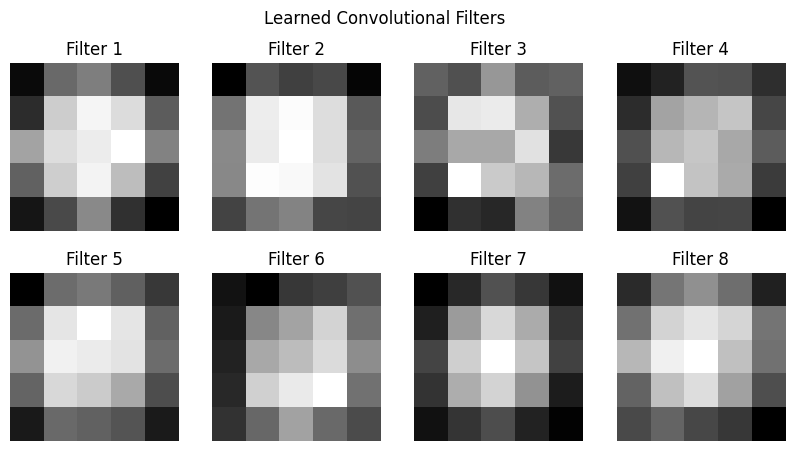

In [4]:
# Visualize weight filters learned by ConvRBM
weights = conv_rbm.W.numpy()
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for idx, ax in enumerate(axes.flat):
    ax.imshow(weights[:, :, 0, idx], cmap='gray')
    ax.set_title(f'Filter {idx+1}')
    ax.axis('off')
plt.suptitle("Learned Convolutional Filters")
plt.show()

### Task 4 & 5: Generate Reconstructions and Comparison with Single-Layer RBM

In [5]:
# Baseline: Standard Single-layer RBM Implementation
class SimpleRBM:
    def __init__(self, visible_dim=784, hidden_dim=128):
        self.W = tf.Variable(tf.random.normal([visible_dim, hidden_dim], stddev=0.01))
        self.v_bias = tf.Variable(tf.zeros([visible_dim]))
        self.h_bias = tf.Variable(tf.zeros([hidden_dim]))

    def sample_h(self, v):
        h_act = tf.nn.sigmoid(tf.matmul(v, self.W) + self.h_bias)
        return h_act, tf.where(h_act > tf.random.uniform(tf.shape(h_act)), 1.0, 0.0)

    def sample_v(self, h):
        v_act = tf.nn.sigmoid(tf.matmul(h, tf.transpose(self.W)) + self.v_bias)
        return v_act, tf.where(v_act > tf.random.uniform(tf.shape(v_act)), 1.0, 0.0)

    def train_step(self, v, lr=0.01):
        with tf.GradientTape() as tape:
            h_act, h_sample = self.sample_h(v)
            v_rec_act, v_rec_sample = self.sample_v(h_sample)
            loss = tf.reduce_mean(tf.square(v - v_rec_act))
        grads = tape.gradient(loss, [self.W, self.v_bias, self.h_bias])
        tf.optimizers.Adam(learning_rate=lr).apply_gradients(zip(grads, [self.W, self.v_bias, self.h_bias]))
        return loss

# Train Baseline Standard RBM
simple_rbm = SimpleRBM()
x_train_flat = tf.reshape(x_train_tensor, [-1, 784])
for epoch in range(5):
    epoch_loss = []
    for i in range(0, len(x_train_flat), batch_size):
        batch = x_train_flat[i:i+batch_size]
        loss = simple_rbm.train_step(batch)
        epoch_loss.append(loss.numpy())
    print(f"Standard RBM Epoch {epoch+1}/5 - Loss: {np.mean(epoch_loss):.5f}")

Standard RBM Epoch 1/5 - Loss: 0.06994
Standard RBM Epoch 2/5 - Loss: 0.05151
Standard RBM Epoch 3/5 - Loss: 0.05128
Standard RBM Epoch 4/5 - Loss: 0.05153
Standard RBM Epoch 5/5 - Loss: 0.05183


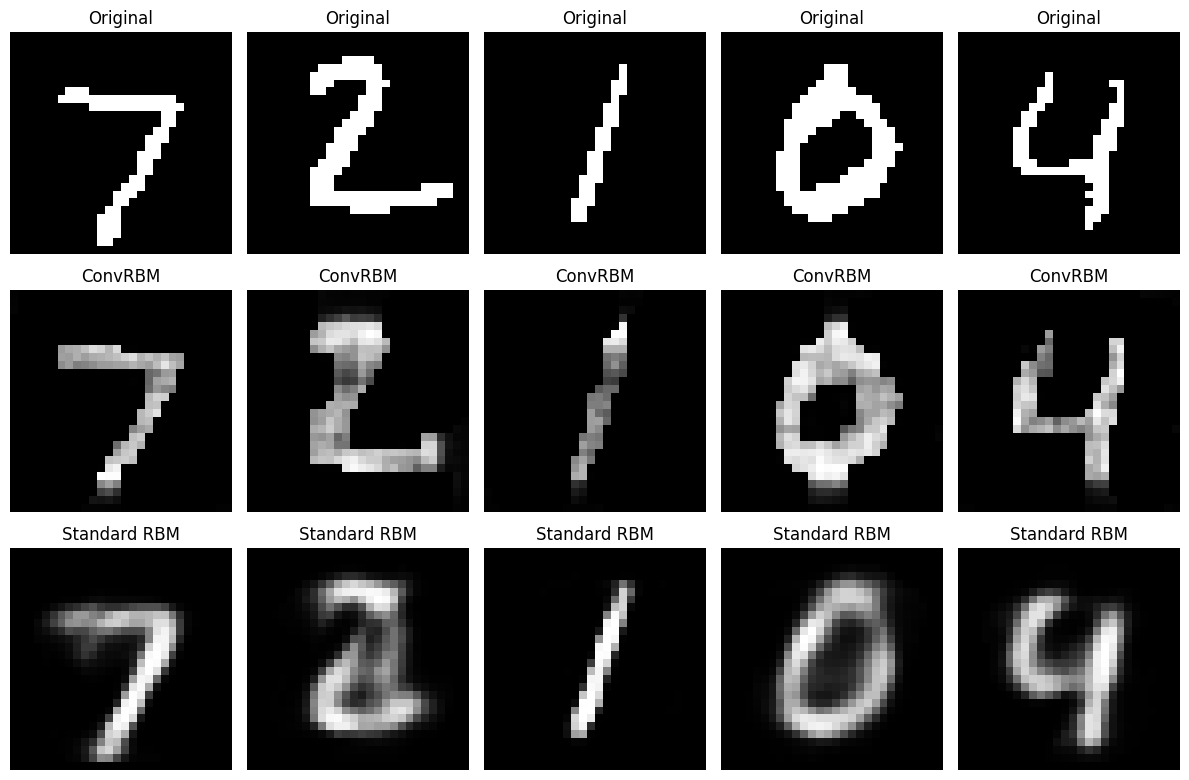

In [6]:
# Generate samples and reconstructions for comparison
test_images = x_test_tensor[:5]
test_images_flat = tf.reshape(test_images, [-1, 784])

# ConvRBM reconstruction
_, h_samples_conv = conv_rbm.sample_h(test_images)
conv_reconstructed, _ = conv_rbm.sample_v(h_samples_conv)

# Standard RBM reconstruction
_, h_samples_simple = simple_rbm.sample_h(test_images_flat)
simple_reconstructed, _ = simple_rbm.sample_v(h_samples_simple)
simple_reconstructed_img = tf.reshape(simple_reconstructed, [-1, 28, 28, 1])

# Plot comparison
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for idx in range(5):
    axes[0, idx].imshow(test_images[idx, :, :, 0], cmap='gray')
    axes[0, idx].set_title("Original")
    axes[0, idx].axis('off')

    axes[1, idx].imshow(conv_reconstructed[idx, :, :, 0], cmap='gray')
    axes[1, idx].set_title("ConvRBM")
    axes[1, idx].axis('off')

    axes[2, idx].imshow(simple_reconstructed_img[idx, :, :, 0], cmap='gray')
    axes[2, idx].set_title("Standard RBM")
    axes[2, idx].axis('off')

plt.tight_layout()
plt.show()